In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"idemtutar","key":"9cc1e642dde2707ce34c019009d6ad7d"}'}

In [ ]:
!pip install -q kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets list -s "caltech 101 bounding box"

ref                                              title                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-----------------------------------------------  ----------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
denizedenize/caltech101-subset-object-detection  Caltech101 Subset Object Detection    26501003  2026-05-05 11:25:40.217000             37          0  0.4117647        


In [ ]:
!kaggle datasets download -d denizedenize/caltech101-subset-object-detection
!unzip -q caltech101-subset-object-detection.zip -d veri_seti

Dataset URL: https://www.kaggle.com/datasets/denizedenize/caltech101-subset-object-detection
License(s): Attribution 4.0 International (CC BY 4.0)
100% 25.3M/25.3M [00:01<00:00, 19.2MB/s]



In [ ]:
import os

for kok, klasorler, dosyalar in os.walk("veri_seti"):
    derinlik = kok.count(os.sep)
    if derinlik <= 3:
        print(f"{kok}  ->  {len(klasorler)} klasör, {len(dosyalar)} dosya")

veri_seti  ->  1 klasör, 0 dosya
veri_seti/dataset  ->  2 klasör, 0 dosya
veri_seti/dataset/images  ->  3 klasör, 0 dosya
veri_seti/dataset/images/Faces  ->  0 klasör, 435 dosya
veri_seti/dataset/images/airplanes  ->  0 klasör, 800 dosya
veri_seti/dataset/images/Motorbikes  ->  0 klasör, 798 dosya
veri_seti/dataset/annotations  ->  0 klasör, 3 dosya


In [ ]:
import os

ann_klasoru = "veri_seti/dataset/annotations"
print("Dosyalar:", os.listdir(ann_klasoru))

for ad in os.listdir(ann_klasoru):
    yol = os.path.join(ann_klasoru, ad)
    satirlar = open(yol).read().strip().split("\n")
    print("\n---", ad, "| satır sayısı:", len(satirlar))
    for s in satirlar[:3]:
        print(s)

Dosyalar: ['Faces.csv', 'airplanes.csv', 'Motorbikes.csv']

--- Faces.csv | satır sayısı: 435
image_0001.jpg,251,15,444,300,Faces
image_0002.jpg,106,31,296,310,Faces
image_0003.jpg,207,17,385,279,Faces

--- airplanes.csv | satır sayısı: 800
image_0001.jpg,49,30,349,137,airplanes
image_0002.jpg,59,35,342,153,airplanes
image_0003.jpg,47,36,331,135,airplanes

--- Motorbikes.csv | satır sayısı: 798
image_0001.jpg,31,19,233,141,Motorbikes
image_0002.jpg,32,15,232,142,Motorbikes
image_0003.jpg,30,20,234,143,Motorbikes


In [ ]:
!pip install -q imutils
!mkdir -p pyimagesearch output/plots
!touch pyimagesearch/__init__.py

In [ ]:
%%writefile pyimagesearch/config.py
# import the necessary packages
import torch
import os

# veri setinin yolu (Kaggle'dan indirdigimiz klasor)
BASE_PATH = "veri_seti/dataset"
IMAGES_PATH = os.path.sep.join([BASE_PATH, "images"])
ANNOTS_PATH = os.path.sep.join([BASE_PATH, "annotations"])

# cikti klasoru
BASE_OUTPUT = "output"

# model, label encoder, grafik ve test yollari
MODEL_PATH = os.path.sep.join([BASE_OUTPUT, "detector.pth"])
LE_PATH = os.path.sep.join([BASE_OUTPUT, "le.pickle"])
PLOTS_PATH = os.path.sep.join([BASE_OUTPUT, "plots"])
TEST_PATHS = os.path.sep.join([BASE_OUTPUT, "test_paths.txt"])

# GPU varsa onu kullan
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PIN_MEMORY = True if DEVICE == "cuda" else False

# ImageNet ortalama ve standart sapma
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# ogrenme orani, epoch sayisi, batch size
INIT_LR = 1e-4
NUM_EPOCHS = 20
BATCH_SIZE = 32

# kayip agirliklari
LABELS = 1.0
BBOX = 1.0

Writing pyimagesearch/config.py


In [ ]:
%%writefile pyimagesearch/custom_tensor_dataset.py
# import the necessary packages
from torch.utils.data import Dataset

class CustomTensorDataset(Dataset):
	# initialize the constructor
	def __init__(self, tensors, transforms=None):
		self.tensors = tensors
		self.transforms = transforms

	def __getitem__(self, index):
		# grab the image, label, and its bounding box coordinates
		image = self.tensors[0][index]
		label = self.tensors[1][index]
		bbox = self.tensors[2][index]

		# transpose the image such that its channel dimension becomes
		# the leading one
		image = image.permute(2, 0, 1)

		# check to see if we have any image transformations to apply
		# and if so, apply them
		if self.transforms:
			image = self.transforms(image)

		# return a tuple of the images, labels, and bounding
		# box coordinates
		return (image, label, bbox)

	def __len__(self):
		# return the size of the dataset
		return self.tensors[0].size(0)

Writing pyimagesearch/custom_tensor_dataset.py


In [ ]:
%%writefile pyimagesearch/bbox_regressor.py
# import the necessary packages
from torch.nn import Dropout
from torch.nn import Identity
from torch.nn import Linear
from torch.nn import Module
from torch.nn import ReLU
from torch.nn import Sequential
from torch.nn import Sigmoid

class ObjectDetector(Module):
	def __init__(self, baseModel, numClasses):
		super(ObjectDetector, self).__init__()

		# initialize the base model and the number of classes
		self.baseModel = baseModel
		self.numClasses = numClasses

		# build the regressor head for outputting the bounding box
		# coordinates
		self.regressor = Sequential(
			Linear(baseModel.fc.in_features, 128),
			ReLU(),
			Linear(128, 64),
			ReLU(),
			Linear(64, 32),
			ReLU(),
			Linear(32, 4),
			Sigmoid()
		)

		# build the classifier head to predict the class labels
		self.classifier = Sequential(
			Linear(baseModel.fc.in_features, 512),
			ReLU(),
			Dropout(),
			Linear(512, 512),
			ReLU(),
			Dropout(),
			Linear(512, self.numClasses)
		)

		# set the classifier of our base model to produce outputs
		# from the last convolution block
		self.baseModel.fc = Identity()

	def forward(self, x):
		# pass the inputs through the base model and then obtain
		# predictions from two different branches of the network
		features = self.baseModel(x)
		bboxes = self.regressor(features)
		classLogits = self.classifier(features)

		# return the outputs as a tuple
		return (bboxes, classLogits)

Overwriting pyimagesearch/bbox_regressor.py


In [ ]:
!ls pyimagesearch
from pyimagesearch import config
from pyimagesearch.bbox_regressor import ObjectDetector
from pyimagesearch.custom_tensor_dataset import CustomTensorDataset
print("Cihaz:", config.DEVICE)
print("Resim yolu var mı:", __import__("os").path.exists(config.IMAGES_PATH))

bbox_regressor.py  custom_tensor_dataset.py  __pycache__
config.py	   __init__.py
Cihaz: cuda
Resim yolu var mı: True


In [ ]:
# import the necessary packages
from pyimagesearch.bbox_regressor import ObjectDetector
from pyimagesearch.custom_tensor_dataset import CustomTensorDataset
from pyimagesearch import config
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import DataLoader
from torchvision import transforms
from torch.nn import CrossEntropyLoss
from torch.nn import MSELoss
from torch.optim import Adam
from torchvision.models import resnet50, ResNet50_Weights
from sklearn.model_selection import train_test_split
from imutils import paths
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
import pickle
import torch
import time
import cv2
import os

# --------------------------------------------------------------
# 1) Veriyi yukle
# --------------------------------------------------------------
print("[INFO] loading dataset...")
data = []
labels = []
bboxes = []
imagePaths = []

# annotations klasorundeki tum CSV dosyalarini gez
for csvPath in paths.list_files(config.ANNOTS_PATH, validExts=(".csv")):
	rows = open(csvPath).read().strip().split("\n")

	for row in rows:
		# satiri parcala: dosya adi, kutu koordinatlari, sinif adi
		row = row.split(",")
		(filename, startX, startY, endX, endY, label) = row

		# resmin yolunu olustur ve resmi oku
		imagePath = os.path.sep.join([config.IMAGES_PATH, label, filename])
		image = cv2.imread(imagePath)
		if image is None:
			raise FileNotFoundError("Resim okunamadi: " + imagePath)
		(h, w) = image.shape[:2]

		# kutu koordinatlarini 0-1 araligina olcekle
		startX = float(startX) / w
		startY = float(startY) / h
		endX = float(endX) / w
		endY = float(endY) / h

		# BGR -> RGB cevir ve 224x224'e boyutlandir
		image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
		image = cv2.resize(image, (224, 224))

		data.append(image)
		labels.append(label)
		bboxes.append((startX, startY, endX, endY))
		imagePaths.append(imagePath)

# SURUM DUZELTMESI: resimleri uint8 tut (float32 yapma).
# ToPILImage float tensoru 0-1 arasi bekler; 0-255 float verilirse
# degerler bozulur. predict tarafi da uint8 kullandigi icin boylece tutarli olur.
data = np.array(data, dtype="uint8")
labels = np.array(labels)
bboxes = np.array(bboxes, dtype="float32")
imagePaths = np.array(imagePaths)

# sinif adlarini sayilara cevir
le = LabelEncoder()
labels = le.fit_transform(labels)
print("[INFO] siniflar:", list(le.classes_))

# %80 egitim, %20 test
split = train_test_split(data, labels, bboxes, imagePaths,
	test_size=0.20, random_state=42)
(trainImages, testImages) = split[:2]
(trainLabels, testLabels) = split[2:4]
(trainBBoxes, testBBoxes) = split[4:6]
(trainPaths, testPaths) = split[6:]

# numpy -> torch tensor
(trainImages, testImages) = torch.tensor(trainImages), torch.tensor(testImages)
(trainLabels, testLabels) = torch.tensor(trainLabels), torch.tensor(testLabels)
(trainBBoxes, testBBoxes) = torch.tensor(trainBBoxes), torch.tensor(testBBoxes)

# normalizasyon (degisken adi "transform": torchvision.transforms modulunu ezmesin)
transform = transforms.Compose([
	transforms.ToPILImage(),
	transforms.ToTensor(),
	transforms.Normalize(mean=config.MEAN, std=config.STD)
])

trainDS = CustomTensorDataset((trainImages, trainLabels, trainBBoxes),
	transforms=transform)
testDS = CustomTensorDataset((testImages, testLabels, testBBoxes),
	transforms=transform)
print("[INFO] total training samples: {}...".format(len(trainDS)))
print("[INFO] total test samples: {}...".format(len(testDS)))

# Colab'da 2 CPU var, num_workers=2 yeterli
trainLoader = DataLoader(trainDS, batch_size=config.BATCH_SIZE,
	shuffle=True, num_workers=2, pin_memory=config.PIN_MEMORY)
testLoader = DataLoader(testDS, batch_size=config.BATCH_SIZE,
	num_workers=2, pin_memory=config.PIN_MEMORY)

# test resimlerinin yollarini kaydet
print("[INFO] saving testing image paths...")
f = open(config.TEST_PATHS, "w")
f.write("\n".join(testPaths))
f.close()

# --------------------------------------------------------------
# 2) Modeli kur
# --------------------------------------------------------------
# SURUM DUZELTMESI: pretrained=True artik kullanilmiyor, weights= kullaniliyor
resnet = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

# ResNet50 katmanlarini dondur (egitimde guncellenmesinler)
for param in resnet.parameters():
	param.requires_grad = False

objectDetector = ObjectDetector(resnet, len(le.classes_))
objectDetector = objectDetector.to(config.DEVICE)

classLossFunc = CrossEntropyLoss()
bboxLossFunc = MSELoss()

# sadece yeni eklenen kafalar egitilecek
opt = Adam(objectDetector.parameters(), lr=config.INIT_LR)

H = {
	"total_train_loss": [],
	"total_val_loss": [],
	"train_class_acc": [],
	"val_class_acc": []
}

[INFO] loading dataset...
[INFO] siniflar: [np.str_('Faces'), np.str_('Motorbikes'), np.str_('airplanes')]
[INFO] total training samples: 1626...
[INFO] total test samples: 407...
[INFO] saving testing image paths...


In [ ]:
print("[INFO] training network...")
startTime = time.time()

for epoch in range(config.NUM_EPOCHS):
	# Modeli egitim moduna al
	objectDetector.train()

	# Toplam egitim ve dogrulama kayiplarini sifirla
	totalTrainLoss = 0
	totalValLoss = 0

	# Egitim setindeki dogru siniflandirma sayisini sifirla
	trainCorrect = 0
	valCorrect = 0

	# Egitim veri yukleyicisi uzerinde dongu kur
	for (images, labels, bboxes) in tqdm(trainLoader, desc=f"Epoch {epoch + 1}/{config.NUM_EPOCHS}"):
		# Verileri cihaza gonder
		(images, labels, bboxes) = (images.to(config.DEVICE),
			labels.to(config.DEVICE), bboxes.to(config.DEVICE))

		# Ileri besleme (forward pass) yap
		(predictions, classLogits) = objectDetector(images)

		# Kayiplari hesapla
		bboxLoss = bboxLossFunc(predictions, bboxes)
		classLoss = classLossFunc(classLogits, labels)
		totalLoss = (config.BBOX * bboxLoss) + (config.LABELS * classLoss)

		# Gradyanlari sifirla, geri besleme (backward pass) yap ve agirliklari guncelle
		opt.zero_grad()
		totalLoss.backward()
		opt.step()

		# Toplam kaybi ekle ve dogru tahmin sayisini guncelle
		totalTrainLoss += totalLoss.item()
		trainCorrect += (classLogits.argmax(1) == labels).type(torch.float).sum().item()

	# Modeli degerlendirme moduna al
	objectDetector.eval()

	# Degerlendirme sirasinda gradyan hesaplamasini kapat
	with torch.no_grad():
		for (images, labels, bboxes) in testLoader:
			(images, labels, bboxes) = (images.to(config.DEVICE),
				labels.to(config.DEVICE), bboxes.to(config.DEVICE))

			(predictions, classLogits) = objectDetector(images)
			bboxLoss = bboxLossFunc(predictions, bboxes)
			classLoss = classLossFunc(classLogits, labels)
			totalLoss = (config.BBOX * bboxLoss) + (config.LABELS * classLoss)

			totalValLoss += totalLoss.item()
			valCorrect += (classLogits.argmax(1) == labels).type(torch.float).sum().item()

	# Ortalama kayip ve dogruluklari hesapla
	avgTrainLoss = totalTrainLoss / len(trainLoader)
	avgValLoss = totalValLoss / len(testLoader)

	trainCorrect = trainCorrect / len(trainDS)
	valCorrect = valCorrect / len(testDS)

	# Gecmis bilgilerini guncelle
	H["total_train_loss"].append(avgTrainLoss)
	H["total_val_loss"].append(avgValLoss)
	H["train_class_acc"].append(trainCorrect)
	H["val_class_acc"].append(valCorrect)

	# Bilgileri ekrana yazdir
	print(f"[INFO] EPOCH: {epoch + 1}/{config.NUM_EPOCHS}")
	print(f"Train loss: {avgTrainLoss:.4f}, Train accuracy: {trainCorrect:.4f}")
	print(f"Val loss: {avgValLoss:.4f}, Val accuracy: {valCorrect:.4f}\n")

endTime = time.time()
print(f"[INFO] Toplam egitim suresi: {endTime - startTime:.2f} saniye")

# Modeli disket uzerine kaydet
print("[INFO] saving object detector model...")
torch.save(objectDetector, config.MODEL_PATH)

# Label encoder'i kaydet
print("[INFO] saving label encoder...")
f = open(config.LE_PATH, "wb")
f.write(pickle.dumps(le))
f.close()

[INFO] training network...


Epoch 1/20: 100%|██████████| 51/51 [00:07<00:00,  6.42it/s]


[INFO] EPOCH: 1/20
Train loss: 0.6502, Train accuracy: 0.8530
Val loss: 0.1075, Val accuracy: 1.0000



Epoch 2/20: 100%|██████████| 51/51 [00:05<00:00,  9.44it/s]


[INFO] EPOCH: 2/20
Train loss: 0.0855, Train accuracy: 0.9926
Val loss: 0.0170, Val accuracy: 1.0000



Epoch 3/20: 100%|██████████| 51/51 [00:05<00:00,  9.67it/s]


... (31 outputs left out)

Epoch 19/20: 100%|██████████| 51/51 [00:05<00:00,  8.67it/s]


[INFO] EPOCH: 19/20
Train loss: 0.0046, Train accuracy: 1.0000
Val loss: 0.0032, Val accuracy: 1.0000



Epoch 20/20: 100%|██████████| 51/51 [00:05<00:00,  8.84it/s]


[INFO] EPOCH: 20/20
Train loss: 0.0039, Train accuracy: 1.0000
Val loss: 0.0030, Val accuracy: 1.0000

[INFO] Toplam egitim suresi: 143.36 saniye
[INFO] saving object detector model...
[INFO] saving label encoder...


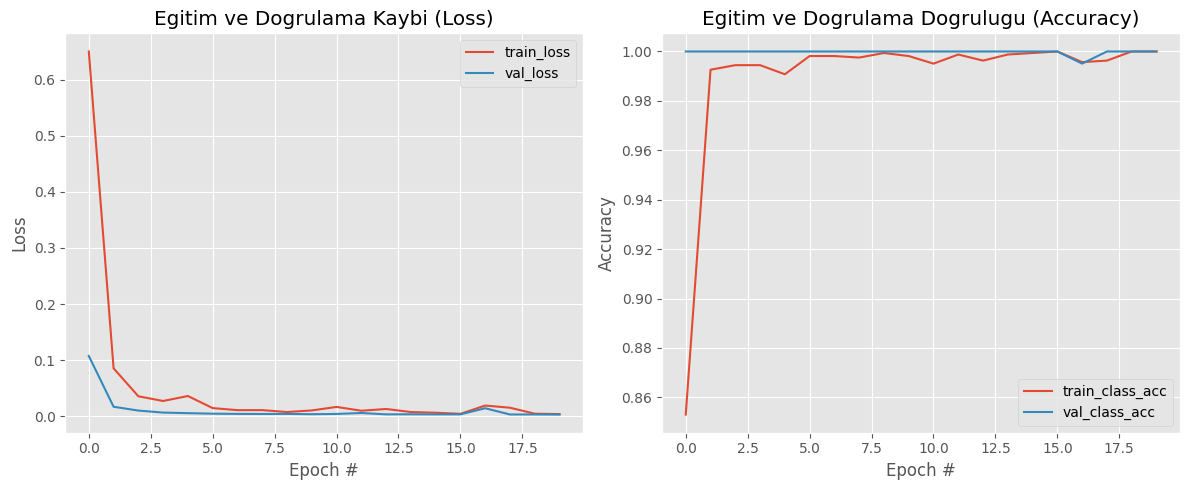

In [ ]:
import matplotlib.pyplot as plt

# Egitim sonuclarini grafiklestirelim
plt.style.use("ggplot")
plt.figure(figsize=(12, 5))

# Loss grafigi
plt.subplot(1, 2, 1)
plt.plot(H["total_train_loss"], label="train_loss")
plt.plot(H["total_val_loss"], label="val_loss")
plt.title("Egitim ve Dogrulama Kaybi (Loss)")
plt.xlabel("Epoch #")
plt.ylabel("Loss")
legend = plt.legend(loc="upper right")

# Accuracy grafigi
plt.subplot(1, 2, 2)
plt.plot(H["train_class_acc"], label="train_class_acc")
plt.plot(H["val_class_acc"], label="val_class_acc")
plt.title("Egitim ve Dogrulama Dogrulugu (Accuracy)")
plt.xlabel("Epoch #")
plt.ylabel("Accuracy")
legend = plt.legend(loc="lower right")

plt.tight_layout()
plt.savefig("output/plots/training_plot.png")
plt.show()

In [ ]:
import numpy as np
import torch
import cv2
import pickle
import os
import random
from torchvision import transforms
from pyimagesearch import config

# Model ve label encoder bir kez yuklenir
model = torch.load(config.MODEL_PATH, map_location=config.DEVICE, weights_only=False)
model.eval()
le = pickle.loads(open(config.LE_PATH, "rb").read())

# Egitimdekiyle AYNI on isleme (ToTensor + ImageNet normalizasyonu)
inference_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean=config.MEAN, std=config.STD)
])

def predict_image(image_path):
    """Girdi: resim dosyasi yolu. Cikti: (etiket, olasilik)"""
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(f"Resim bulunamadi: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (224, 224))
    image = image.transpose((2, 0, 1))            # kanali basa al (C, H, W)
    image = torch.from_numpy(image)               # uint8 tensor
    image = inference_transform(image).to(config.DEVICE).unsqueeze(0)

    with torch.no_grad():
        (box_preds, class_logits) = model(image)
        probs = torch.nn.functional.softmax(class_logits, dim=-1)
        confidence, pred_idx = probs.max(dim=-1)

    pred_label = str(le.inverse_transform(pred_idx.cpu().numpy())[0])
    return pred_label, float(confidence.item())

In [ ]:
# Test setinden farkli bir rastgele gorsel secip tahmin edelim
import random

# Ilk gorselden (testPaths[0]) farkli olması icin rastgele bir indeks secelim
random_index = random.randint(1, len(testPaths) - 1)
random_test_image_path = testPaths[random_index]

# Tahmini gerceklestir
predicted_label, confidence_score = predict_image(random_test_image_path)

print(f"Secilen Test Indeksi: {random_index}")
print(f"Test Resmi Yolu: {random_test_image_path}")
print(f"Model Tahmini: {predicted_label}")
print(f"Guven Orani: %{confidence_score * 100:.2f}")

Secilen Test Indeksi: 265
Test Resmi Yolu: veri_seti/dataset/images/Faces/image_0317.jpg
Model Tahmini: Faces
Guven Orani: %99.99


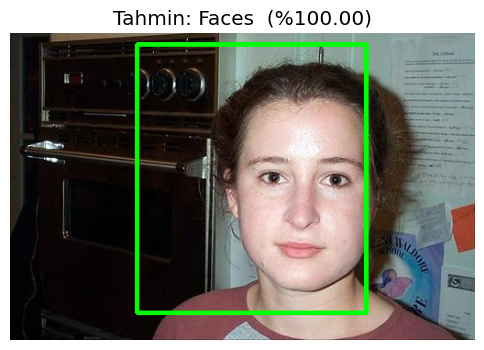

In [ ]:
import matplotlib.pyplot as plt

def goster(image_path):
    orig = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    (h, w) = orig.shape[:2]

    # modele ayni on isleme ile ver
    img = cv2.resize(orig, (224, 224)).transpose((2, 0, 1))
    img = inference_transform(torch.from_numpy(img)).to(config.DEVICE).unsqueeze(0)

    with torch.no_grad():
        (box, logits) = model(img)
        probs = torch.nn.functional.softmax(logits, dim=-1)
        p, i = probs.max(dim=-1)

    etiket = str(le.inverse_transform(i.cpu().numpy())[0])
    (sx, sy, ex, ey) = box[0].cpu().numpy()

    # kutuyu orijinal resmin boyutuna gore ciz
    cv2.rectangle(orig, (int(sx*w), int(sy*h)), (int(ex*w), int(ey*h)), (0, 255, 0), 3)

    plt.figure(figsize=(6, 5))
    plt.imshow(orig)
    plt.title(f"Tahmin: {etiket}  (%{p.item()*100:.2f})")
    plt.axis("off")
    plt.show()

goster("veri_seti/dataset/images/Faces/image_0131.jpg")

Yeni Seçilen Test Görseli: veri_seti/dataset/images/airplanes/image_0731.jpg


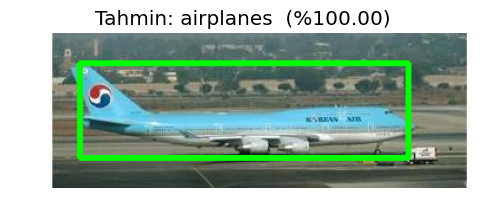

In [ ]:
# Test kümesinden yeni bir rastgele görsel seçelim
random_test_idx = random.randint(0, len(testPaths) - 1)
yeni_resim_yolu = testPaths[random_test_idx]

print(f"Yeni Seçilen Test Görseli: {yeni_resim_yolu}")
# Resmi hem sınıflandırıp hem de çerçevesiyle birlikte ekranda gösterelim
goster(yeni_resim_yolu)